In [1]:
import os
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np
from pickle import dump


import json
import matplotlib.pyplot as plt
from typing import Iterable
from tensorflow.keras.optimizers import Adam
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.metrics import mean_absolute_error


from keras.layers import Dense, BatchNormalization, Activation, Add, Input

from keras.models import model_from_json
from keras.regularizers import l2, l1_l2
from keras import Model
from tensorflow import Tensor
from typing import List
from tensorflow.keras.optimizers import Adam

import math

from pickle import load

In [2]:
def load_time_based_data(directory):
    """
    function for loading the time based data
    returns(2): list of each data, and names of each data
    """
    dfs = []
    df_time_names=[]
    count = 0
    for subdir, dirs, files in os.walk(directory):
        for file in files:
            filename = directory + '/'+file
            if filename.endswith(".csv") and "time" in filename:
                df = pd.read_csv(filename, sep=',', decimal='.')
                wellname = file.split('.csv')
                df['WellName'] = wellname[0]
                df_time_names.append(wellname[0])
                dfs.append(df)
                count += 1
                
                
    return dfs,df_time_names



In [3]:
def MAE_moving_window(trueValues:list, predValues:list, windowSize=5000):
    """
    used for computing the mean absolute error at every window
    returns the list of computed MAE and another list for window index
    """
    startIndex=0
    endIndex=windowSize
    MAElist=[]
    windowsList=[]
    numWindows = math.ceil(len(trueValues)/windowSize)

    for i in range(numWindows):
   
        if i== numWindows-1:
            meanAbsError = mean_absolute_error(trueValues[startIndex:], predValues[startIndex:])
            endIndex=len(trueValues) 
        else:
            meanAbsError = mean_absolute_error(trueValues[startIndex:endIndex], predValues[startIndex:endIndex])
            
        MAElist.append(meanAbsError)
        windowsList.append(endIndex-1)
        startIndex = endIndex
        endIndex=endIndex+windowSize

       
    
    return MAElist, windowsList


In [4]:

def subplots_array(data ,input_var:list,output_var, y_axisdata):

    """
    This function is for building horizontal subplots with same y axis.
    :data: array containing the input, output and predicted data
    :input_var: input variables based on columns of csv files
    :output_var: output variables based on columns of csv files
    :y_axisdata: variable based on columns of csv files. e.g. bitDpeht in this case

    """
    fig,axs= plt.subplots(1, (data.shape[1]-1), sharey=True)
    fig.set_figheight(12)
    fig.set_figwidth(14)
    y=y_axisdata
    
    #range is subracted with 1 since bit depth not included on x axis data
    for i in range(data.shape[1]-1):
        axs[i].plot(data[:,i],y)
        

        if i < (data.shape[1]-2):
            axs[i].set(xlabel=input_var[i])
        else:
            axs[i].set(xlabel=output_var)

    #plot the last col which is the predicted values
    axs[i].plot(data[:,-1],y)

    #axs[i].set(xlabel=input_var[i])
    
    axs[0].set(ylabel='bit depth (m)')
    axs[0].invert_yaxis()
    return


In [5]:
def plot_compare_predicted_expected(testY,yPred, output_var, x_axisData,title='expected vs predicted',windowSize=False):
    """
    plotting the predicted and expected values
    optional to have the moving MAE window
    :testY: test data outpout (ROP)
    :yPred: predicted output (ROP)
    :x_axisData: data for x axis (bitDpeth) in our case
    :windowSize: int
    """
    
    bitDepth = x_axisData
    fig, ax1 = plt.subplots(figsize=(20, 6), dpi=60)

    ax1.plot(bitDepth,yPred, label='predicted')
    ax1.plot(bitDepth,testY, label=f'expected{output_var}') 
    ax1.set_ylabel(output_var)
    ax1.set_xlabel('bit Depth (m)')
    ax1.legend()
    
    if windowSize:
        maeList, windowsList = MAE_moving_window(testY, yPred, windowSize)
        ax2 = ax1.twinx()
        bitDepth_of_windows= [bitDepth[i] for i in windowsList]
        ax2.plot(bitDepth_of_windows, maeList, color='green', linestyle='--', marker='o')
        ax2.set_ylim(0, max(maeList))
        ax2.set_ylabel('MAE')
        ax2.legend()
     
        
    fig.tight_layout()
    
    plt.title(title)

   
    
    plt.show()


In [6]:
def plot_train_history(
    train_loss: Iterable, 
 
    loss_func: str, 
    fig_path: str,
):

    plt.figure()
    plt.plot(train_loss, label='Training set')

    plt.title("Training history")
    plt.xlabel('Epochs')
    plt.ylabel(f"Loss ({loss_func})")
    plt.legend()
    plt.savefig(fig_path, dpi=170, bbox_inches='tight')
    plt.show()
    plt.clf()
    plt.close()

    return

In [7]:
def preProcess(datafolder,
                input_var_list, 
                output_var, 
                training_dfs,
                train_percent
 
                ):
    """
    :input_var_list: list containing input variables (refers to column name in the data)
    :output_var: output variable. e.g. ROP
    :training_dfs: csv files chosen for retraining
    :train_percent: proportion used for splitting data e.g. 0.1 means first 10% for training and 90% for testing

    scaler_option default is  'min_maxScaler'
    
    """
    
    time_data, df_time_names = load_time_based_data(datafolder)
    


 
    #concatenate all TIME datasets
    all_data_concat = pd.DataFrame()
    for dataset in df_time_names:
        idx = df_time_names.index(dataset)
        all_data_concat = pd.concat([all_data_concat,time_data[idx]])



    #make an array of all datasets with columns of input vriables   
    inputs = np.zeros([len(all_data_concat),len(input_var_list)])
    for i in range(len(input_var_list)):
        inputs[:,i] = all_data_concat[input_var_list[i]]

    #fit a scaler to all time datasets
    scaler = MinMaxScaler()
    scaler.fit(inputs)
    ##
    dump(scaler, open('scaler.pkl', 'wb'))

    
    #SPLIT DATA
    #get the chosen file from the dataset
    dataset = training_dfs

    try:
        idx = df_time_names.index(dataset)
        current_well_data = time_data[idx]
        
    #in case the data is outside volve field    
    except:
        dataset = datafolder + "/" + dataset
        current_well_data  = pd.read_csv(dataset)

    num_observations = current_well_data.shape[0]

    #split data index
    train_index=int(num_observations*train_percent)

    #split data
    training_data_concat = current_well_data[:train_index]
    testing_data_concat = current_well_data[train_index:]

                
    #prepare input frame
    train_input = np.zeros([len(training_data_concat),len(input_var_list)])
    test_input = np.zeros([len(testing_data_concat),len(input_var_list)])

    for i in range(len(input_var_list)):
        train_input[:,i] = training_data_concat[input_var_list[i]]
        test_input[:,i] = testing_data_concat[input_var_list[i]]

    #scale input
    scaled_train_input= scaler.transform(train_input)
    scaled_test_input= scaler.transform(test_input)
    
    #prepare output
    train_output = np.expand_dims(training_data_concat[output_var], 1)
    test_output = np.expand_dims(testing_data_concat[output_var], 1)
        
    #bit depth data for test data #used for visualization
    bitDepth = np.expand_dims(testing_data_concat["Bit Measured Depth m"], 1)  

    return [scaled_train_input,train_output,scaled_test_input,test_output, bitDepth]
    

### Configurations (please change the json file and datafolder if needed)

In [8]:
# Opening JSON file
f = open('/Users/fjpax/Desktop/Volve clean/config2/config_test10.json')
 
# returns JSON object as a dictionary
config = json.load(f)

#path for files
datafolder = "/Users/fjpax/OneDrive - Universitetet i Stavanger/Volve Datasets/Processed Drilling Data"

#base_model file name
base_model_name = "final model.h5"

In [9]:
retrainX, retrainY, testX, testY,bitDepth= preProcess(datafolder,
                                            input_var_list=config['input_var_list'], 
                                            output_var=config['output_var_list'], 
                                            training_dfs=config['training_dfs'],
                                            train_percent=config['train_percent'])

In [10]:
#modify base model : renaming the base model as modifiedBaseModel
modifiedBaseModel=keras.models.load_model(base_model_name)    #Total params: 9,281 Trainable params: 4,289 Non-trainable params: 4,992
for layer in modifiedBaseModel.layers[:-4]:
        layer.trainable = False
modifiedBaseModel.layers[-3].trainable=False #freeze the batch normalization layer

#model graph
modifiedBaseModel.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 4)]               0         
_________________________________________________________________
dense (Dense)                (None, 64)                256       
_________________________________________________________________
batch_normalization (BatchNo (None, 64)                256       
_________________________________________________________________
activation (Activation)      (None, 64)                0         
_________________________________________________________________
dense_1 (Dense)              (None, 64)                4096      
_________________________________________________________________
batch_normalization_1 (Batch (None, 64)                256       
_________________________________________________________________
activation_1 (Activation)    (None, 64)                0     

2021-12-07 17:45:14.616088: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [11]:
#compile model
modifiedBaseModel.compile(optimizer=Adam(learning_rate=config['l_r']), loss=config['loss_func'])

### Retrain model

In [12]:
#callbacks
callbackList = [
                    keras.callbacks.EarlyStopping(
                    monitor="loss",
                    patience=50,
                    )]

In [13]:
#fit modified base model
history = modifiedBaseModel.fit(
        retrainX, 
        retrainY,
        epochs=config['n_epochs'], 
        batch_size=config['batch_size'], 
        verbose=config['verbose'], 
        callbacks=callbackList)

2021-12-07 17:45:14.972233: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


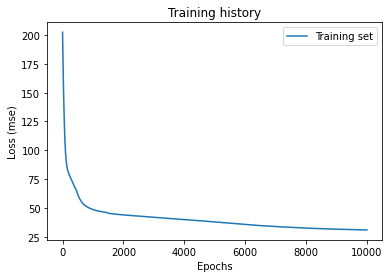

In [14]:
# plot of the training history
plot_train_history(train_loss=history.history['loss'], 
                        loss_func=config['loss_func'], 
                        fig_path=config['fig_path']
                        #val_loss=history.history['val_loss'], 
                        )
        

### Test the new model on test data

No handles with labels found to put in legend.


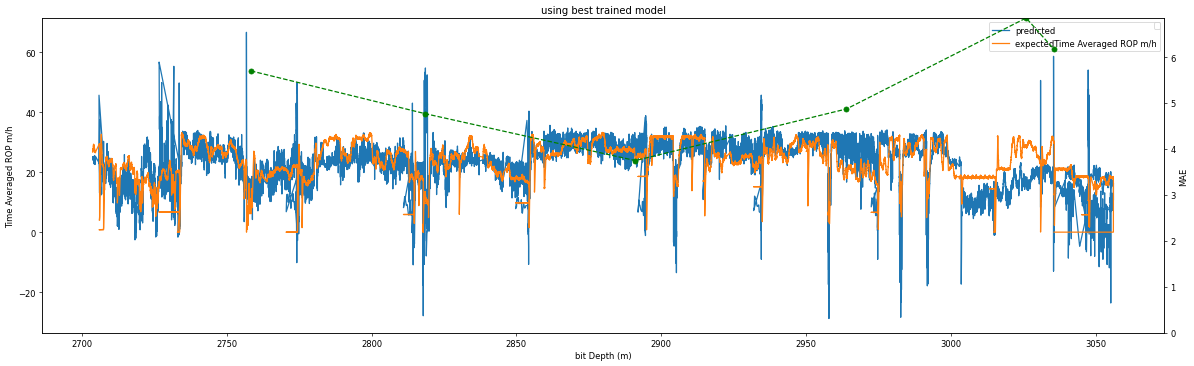

In [15]:
#final best retrained model
yPred_retrained =  modifiedBaseModel.predict(testX)  
plot_compare_predicted_expected(testY,yPred_retrained , x_axisData=bitDepth, output_var=config['output_var_list'], title='using best trained model',windowSize=4000)
        

### Test the Original base model on test data

No handles with labels found to put in legend.


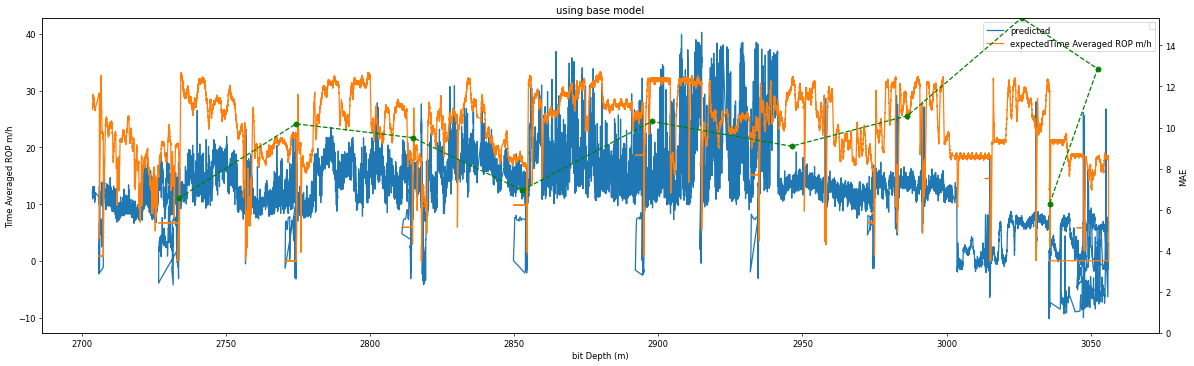

In [16]:
#basemodel
reloadmodel= keras.models.load_model(base_model_name)

#predict on test data
yPred= reloadmodel.predict(testX)

#plot
plot_compare_predicted_expected(testY,yPred,x_axisData=bitDepth, output_var=config['output_var_list'],title='using base model' ,windowSize=2500)


### subplot of input, output, and predicted ROP as function of bitDepth

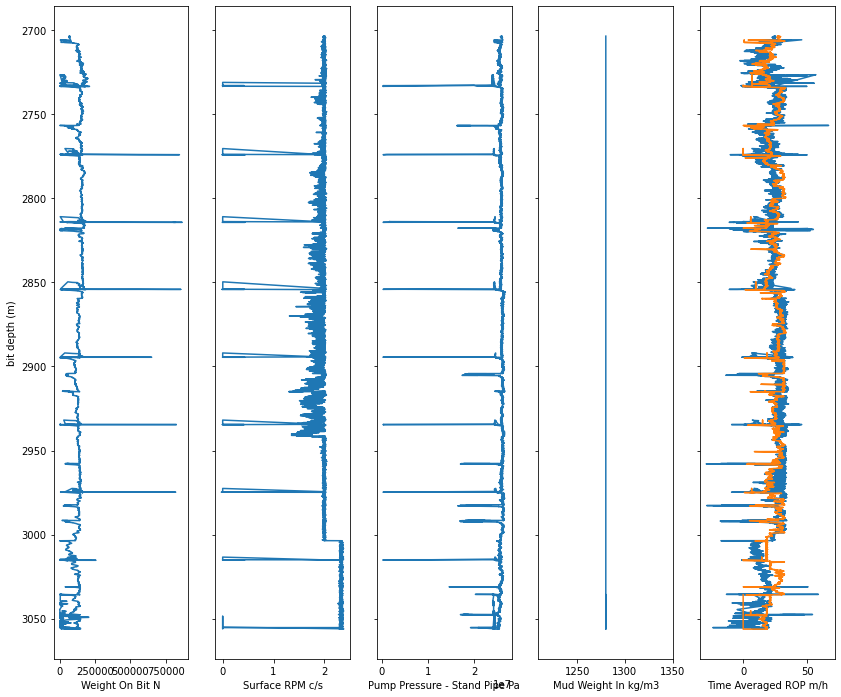

In [17]:
#scale back the data
scaler = load(open('scaler.pkl', 'rb'))
testX_transformed_orig = scaler.inverse_transform(testX)

#add the predicted array to the transformed back array
orig_data = np.append(testX_transformed_orig, yPred_retrained , axis=1)

#append the textY to the array
orig_data = np.append(orig_data, testY, axis=1)

#show subplot
subplots_array(orig_data,config['input_var_list'], config['output_var_list'], bitDepth)


# Train new model with same architecture

In [18]:

def bn_layer(
    x: Tensor, 
    hidden_units: int,
    l1_lambda: float = 0.0001, 
    l2_lambda: float = 0.0005, 
    act_func: str = 'relu'
) -> Tensor:
    """
    Convenience function for adding batch normed layers to a Keras model defined using 
    the functional API (will not work if using Sequential models API).
    Call during model definition to add to Tensorflow computational graph.
    :param x: Tensor output of previous layer, assumes it is same size as hidden_units
    :param hidden_units: Number of hidden units in layer.
    :param l1_lambda: Float value for L1 regularization lamda parameter (feature selection)
    :param l2_lambda: Float value for L2 regularization lamda parameter (weight decay)
    :param act_func: Valid string alias for Tensorflow activation functions.
    :return: Tensor, output of the residual block.  
    """
    y = Dense(hidden_units, 
              kernel_regularizer=l1_l2(l1=l1_lambda, l2=l2_lambda), 
              use_bias=False)(x)
    y = BatchNormalization()(y)
    y = Activation(act_func)(y)

    return y


def get_nn_model(
    n_input_vars: int,
    n_outputs: int = 1,
    fc_layer_sizes: List[int] = [32, 32],
    l1_lambda: float = 0.001,
    l2_lambda: float = 0.005,
    act_func: str = 'relu',
    loss_func: str = 'mean_absolute_error',
    out_activation: str = 'linear',
    l_r: float = 0.02,
    return_json: bool = False
):
    """
    Convenience function for defining a simple configurable feed-forward neural network model, 
    for either regression or classification.
    Default settings are for regression model, for classification use sigmoid or softmax 
    output activation, and cross-entropy for loss.

    :param n_input_vars: Int number of input variables.
    :param n_outputs: Int number of output units.
    :param fc_layer_sizes: Int number of hidden units in hidden layers.
    :param l1_lambda: Float value for L1 regularization lamda parameter (feature selection)
    :param l2_lambda: Float value for L2 regularization lamda parameter (weight decay)
    :param act_func: String alias for activation functions to use in hidden layers.
    :param loss_func: String alias for loss function to use for training.
    :param out_activation: String alias for output layer activation function
    :param l_r: Learning rate to pass to Model.compile()
    :param return_json: Specifies whether to return the model object or a JSON string 
                        representation of model.
    :return: Keras Model or JSON representation.
    """

    inputs = Input(shape=(n_input_vars,)) #Input() is used to instantiate a Keras tensor.  indicates that the expected input will be batches of 32-dimensional vectors.

    # NOTE - for tensor addition to work, input tensor size should be compatible 
    # with hidden units value passed to res block

    x = inputs

    # Add hidden layers to model
    for layer_size in fc_layer_sizes:
        x = bn_layer(x=x, hidden_units=layer_size, l1_lambda=l1_lambda, 
                     l2_lambda=l2_lambda, act_func=act_func)

    # Final layer
    output = Dense(n_outputs, activation=out_activation)(x)

    model = Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=l_r), loss=loss_func)

    if return_json:
        m_json = model.to_json()
        return m_json
    else:
        return model

### New model Configs (please change the json file and datafolder if needed)

In [19]:
# Opening JSON file
f = open('/Users/fjpax/Desktop/Volve clean/config2/config_newModel10.json')
 
# returns JSON object as a dictionary
config = json.load(f)

#path for files
datafolder = "/Users/fjpax/OneDrive - Universitetet i Stavanger/Volve Datasets/Processed Drilling Data"


In [20]:
trainX, trainY, testX, testY,bitDepth= preProcess(datafolder,
                                            input_var_list=config['input_var_list'], 
                                            output_var=config['output_var_list'], 
                                            training_dfs=config['training_dfs'],
                                           
                                            train_percent=config['train_percent'])

### Build model

In [21]:
my_model = get_nn_model(
            n_input_vars=config['n_inputs'],
            n_outputs=config['n_outputs'],
            fc_layer_sizes=config['layer_sizes'],
            l1_lambda=config['l1_lambda'],
            l2_lambda=config['l2_lambda'],
            act_func=config['act_func'],
            loss_func=config['loss_func'],
            out_activation=config['output_activation'],
            return_json=False  
            )   

### Fit new model

##### difference  of new model from the trained base model:
##### 1. no more validation data
##### 2. patience is now based on loss (val loss) --> (from prev model) 

### Fit new model

In [22]:
# add callbacks for training process, e.g. Early Stopping
callbacks_list = [
                    keras.callbacks.EarlyStopping(
                    monitor="loss",
                    patience=100)]#,

                    ###second callback for saving best model based od validation loss
                    #keras.callbacks.ModelCheckpoint(
                    #filepath="checkpoint_path_model.h5",
                    #monitor="val_loss", 
                    #save_best_only=True)] 

# Train a model
history = my_model.fit(
                        trainX, 
                        trainY,
                        epochs=config['n_epochs'], 
                        batch_size=config['batch_size'], 
                        verbose=0, 

                        callbacks=callbacks_list)

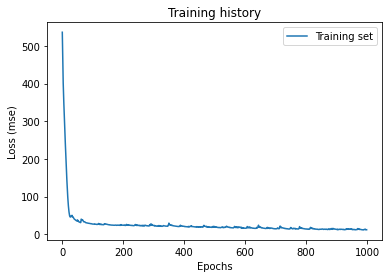

In [23]:
# plot of the training history
plot_train_history(
                    train_loss=history.history['loss'], 
                    
                    loss_func=config['loss_func'], 
                    fig_path=config['fig_path']
                    )

No handles with labels found to put in legend.


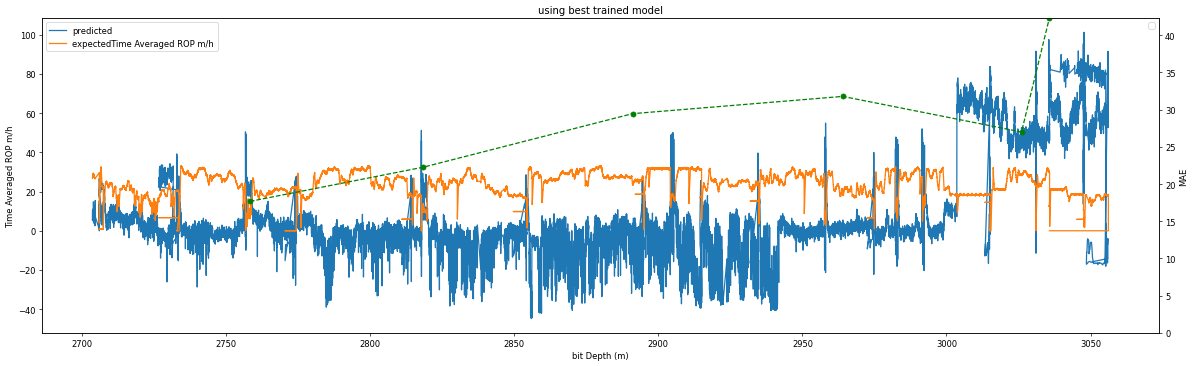

In [24]:
#final best retrained model
yPred_retrained =  my_model.predict(testX)  
plot_compare_predicted_expected(testY,yPred_retrained , x_axisData=bitDepth, output_var=config['output_var_list'], title='using best trained model',windowSize=4000)
        